Device: cpu


Using cache found in /root/.cache/torch/hub/verlab_accelerated_features_main


Saving IMG_3575.jpg to IMG_3575 (6).jpg

XFeat output
Image 1 keypoints: 1000
Image 2 keypoints: 1000
Descriptor dimension: 64

Descriptor value range
Minimum: -0.48466530442237854
Maximum: 0.45030418038368225
Mean: 0.003665156429633498
Standard deviation: 0.12494723498821259
Verified: uint8 ABS and thermometer XOR distance matrices are identical.

========== Accuracy: quantized ordinal distance ==========

A. Original float32 cosine
Mutual matches: 546
Correct matches (< 3 pixels): 368
Precision: 67.40%
Median geometric error: 1.27 pixels

B. Quantile 8-level reconstructed cosine
Mutual matches: 536
Correct matches (< 3 pixels): 351
Precision: 65.49%
Median geometric error: 1.34 pixels

C. Quantile uint8 ABS
Mutual matches: 536
Correct matches (< 3 pixels): 340
Precision: 63.43%
Median geometric error: 1.44 pixels

D. Quantile 7-bit thermometer XOR + popcount
Mutual matches: 536
Correct matches (< 3 pixels): 340
Precision: 63.43%
Median geometric error: 1.44 pixels

Quantile level usa

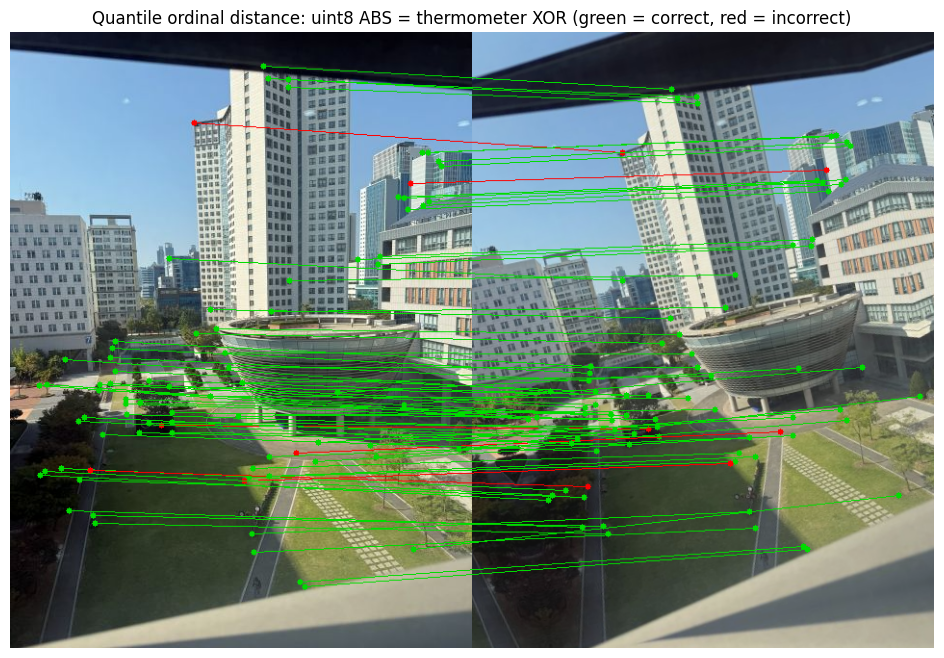

In [10]:
# ============================================================
# XFeat 3-bit descriptor baseline test
# Upload one JPG/PNG image when requested
# ============================================================

!pip -q install opencv-python-headless numba

import io
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

# ------------------------------------------------------------
# 1. Load pretrained XFeat
# ------------------------------------------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"

xfeat = torch.hub.load(
    "verlab/accelerated_features",
    "XFeat",
    pretrained=True,
    top_k=1000
).to(device).eval()

print("Device:", device)


# ------------------------------------------------------------
# 2. Upload one image
# ------------------------------------------------------------

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError(
        "Please upload exactly one JPG or PNG image. "
        "The second image is generated automatically so the ground-truth homography is known."
    )

filename = next(iter(uploaded))

image_bytes = uploaded[filename]

img1 = cv2.imdecode(
    np.frombuffer(image_bytes, np.uint8),
    cv2.IMREAD_COLOR
)

if img1 is None:
    raise ValueError("Please upload a JPG or PNG image.")

# Resize image so that the largest side is at most 640 pixels.
h, w = img1.shape[:2]
scale = min(1.0, 640.0 / max(h, w))

new_w = max(32, (int(w * scale) // 32) * 32)
new_h = max(32, (int(h * scale) // 32) * 32)

img1 = cv2.resize(img1, (new_w, new_h))

h, w = img1.shape[:2]


# ------------------------------------------------------------
# 3. Automatically create a transformed second image
# ------------------------------------------------------------

# Rotate by 12 degrees and slightly reduce scale.
rotation = cv2.getRotationMatrix2D(
    center=(w / 2, h / 2),
    angle=12,
    scale=0.92
)

H = np.vstack([
    rotation,
    [0, 0, 1]
]).astype(np.float32)

img2 = cv2.warpPerspective(
    img1,
    H,
    (w, h),
    flags=cv2.INTER_LINEAR,
    borderMode=cv2.BORDER_REFLECT
)

# Also change the brightness slightly.
img2 = cv2.convertScaleAbs(
    img2,
    alpha=0.90,
    beta=15
)


# ------------------------------------------------------------
# 4. Convert images to PyTorch tensors
# ------------------------------------------------------------

def image_to_tensor(image):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    tensor = torch.from_numpy(rgb.copy())
    tensor = tensor.permute(2, 0, 1).float()
    tensor = tensor.unsqueeze(0) / 255.0

    return tensor.to(device)


x1 = image_to_tensor(img1)
x2 = image_to_tensor(img2)


# ------------------------------------------------------------
# 5. Extract XFeat keypoints and 64-D descriptors
# ------------------------------------------------------------

with torch.no_grad():
    output1 = xfeat.detectAndCompute(x1, top_k=1000)[0]
    output2 = xfeat.detectAndCompute(x2, top_k=1000)[0]

kp1 = output1["keypoints"]
kp2 = output2["keypoints"]

d1 = output1["descriptors"]
d2 = output2["descriptors"]

print("\nXFeat output")
print("Image 1 keypoints:", len(kp1))
print("Image 2 keypoints:", len(kp2))
print("Descriptor dimension:", d1.shape[1])

print("\nDescriptor value range")
print("Minimum:", d1.min().item())
print("Maximum:", d1.max().item())
print("Mean:", d1.mean().item())
print("Standard deviation:", d1.std().item())



# ------------------------------------------------------------
# 6. Quantile 8-level ordinal matching: uint8 ABS vs thermometer XOR
#
# Direct uint8 matching computes sum(abs(level_1 - level_2)).
# Thermometer matching computes the same distance using XOR + popcount.
# Their distance matrices are checked for exact equality before benchmarking.
# ------------------------------------------------------------
import time
import torch.nn.functional as F
from numba import njit, prange

LEVELS = 8
THERMOMETER_BITS = LEVELS - 1
WARMUP = 5
REPEATS = 20

d1_cpu = d1.detach().to("cpu", dtype=torch.float32).contiguous()
d2_cpu = d2.detach().to("cpu", dtype=torch.float32).contiguous()


def fit_quantile_edges(calibration_descriptors):
    quantiles = torch.arange(1, LEVELS, dtype=calibration_descriptors.dtype) / LEVELS
    return torch.quantile(calibration_descriptors, quantiles, dim=0).T.contiguous()


def encode_levels(descriptors, edges):
    """Return quantile level indices from 0 through 7."""
    return (descriptors[:, :, None] > edges[None, :, :]).sum(dim=-1).to(torch.uint8)


def fit_centers(calibration_descriptors, calibration_codes):
    """Representative float values for the reconstructed-cosine control."""
    dimensions = calibration_descriptors.shape[1]
    centers = torch.empty((dimensions, LEVELS), dtype=calibration_descriptors.dtype)
    low = calibration_descriptors.amin(dim=0)
    high = calibration_descriptors.amax(dim=0)
    for level in range(LEVELS):
        mask = calibration_codes == level
        count = mask.sum(dim=0)
        total = (calibration_descriptors * mask).sum(dim=0)
        fallback = low + (high - low) * ((level + 0.5) / LEVELS)
        centers[:, level] = torch.where(count > 0, total / count.clamp_min(1), fallback)
    return centers


def reconstruct(codes, centers):
    dimensions = torch.arange(codes.shape[1])[None, :]
    return centers[dimensions, codes.long()]


def pack_thermometer_codes(level_codes):
    """
    Convert every level k to k one-bits followed by (7-k) zero-bits.
    The 64 components become 64*7=448 bits=56 bytes=7 uint64 words.
    """
    levels = np.ascontiguousarray(level_codes.cpu().numpy(), dtype=np.uint8)
    thermometer_lut = np.asarray([(1 << level) - 1 for level in range(LEVELS)], dtype=np.uint8)
    thermometer = thermometer_lut[levels]
    bit_positions = np.arange(THERMOMETER_BITS, dtype=np.uint8)
    bits = ((thermometer[:, :, None] >> bit_positions[None, None, :]) & 1)
    bits = bits.reshape(levels.shape[0], -1)
    packed_bytes = np.packbits(bits, axis=1, bitorder="little")
    assert packed_bytes.shape[1] == 56
    packed_words = np.ascontiguousarray(packed_bytes).view(np.uint64)
    assert packed_words.shape[1] == 7
    return packed_words


@njit(inline="always")
def popcount_u64(value):
    """Fixed-cost SWAR popcount; LLVM may lower this to hardware POPCNT."""
    value = value - ((value >> np.uint64(1)) & np.uint64(0x5555555555555555))
    value = ((value & np.uint64(0x3333333333333333))
             + ((value >> np.uint64(2)) & np.uint64(0x3333333333333333)))
    value = (value + (value >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return (value * np.uint64(0x0101010101010101)) >> np.uint64(56)


@njit(parallel=True, cache=False)
def pairwise_xor_popcount(packed_1, packed_2):
    """Hamming distance using seven uint64 XOR+popcount operations per pair."""
    number_1, number_2 = packed_1.shape[0], packed_2.shape[0]
    number_of_words = packed_1.shape[1]
    distances = np.empty((number_1, number_2), dtype=np.uint16)
    for i in prange(number_1):
        for j in range(number_2):
            total = 0
            for word in range(number_of_words):
                total += popcount_u64(packed_1[i, word] ^ packed_2[j, word])
            distances[i, j] = total
    return distances


@njit(parallel=True, cache=False)
def pairwise_uint8_abs(levels_1, levels_2):
    """Ordinal L1 distance: sum(abs(level_1 - level_2)) over 64 dimensions."""
    number_1, number_2 = levels_1.shape[0], levels_2.shape[0]
    dimensions = levels_1.shape[1]
    distances = np.empty((number_1, number_2), dtype=np.uint16)
    for i in prange(number_1):
        for j in range(number_2):
            total = 0
            for dimension in range(dimensions):
                left = int(levels_1[i, dimension])
                right = int(levels_2[j, dimension])
                total += left - right if left >= right else right - left
            distances[i, j] = total
    return distances


@torch.inference_mode()
def mutual_match_cosine(descriptors_1, descriptors_2):
    descriptors_1 = F.normalize(descriptors_1, p=2, dim=1)
    descriptors_2 = F.normalize(descriptors_2, p=2, dim=1)
    similarity = descriptors_1 @ descriptors_2.T
    nearest_12 = similarity.argmax(dim=1)
    nearest_21 = similarity.argmax(dim=0)
    indices_1 = torch.arange(descriptors_1.shape[0])
    mutual = nearest_21[nearest_12] == indices_1
    matched_1, matched_2 = indices_1[mutual], nearest_12[mutual]
    return matched_1, matched_2, similarity[matched_1, matched_2]


def mutual_match_distances(distances):
    nearest_12 = distances.argmin(axis=1)
    nearest_21 = distances.argmin(axis=0)
    indices_1 = np.arange(distances.shape[0])
    mutual = nearest_21[nearest_12] == indices_1
    matched_1, matched_2 = indices_1[mutual], nearest_12[mutual]
    scores = distances[matched_1, matched_2]
    return (torch.from_numpy(matched_1), torch.from_numpy(matched_2),
            torch.from_numpy(scores.astype(np.float32)))


def mutual_match_hamming(packed_1, packed_2):
    return mutual_match_distances(pairwise_xor_popcount(packed_1, packed_2))


def mutual_match_uint8_abs(levels_1, levels_2):
    return mutual_match_distances(pairwise_uint8_abs(levels_1, levels_2))


# Fit thresholds on image 1 for this controlled test.
# The final benchmark should fit one fixed codebook on external calibration data.
quantile_edges = fit_quantile_edges(d1_cpu)
quantile_q1 = encode_levels(d1_cpu, quantile_edges)
quantile_q2 = encode_levels(d2_cpu, quantile_edges)
quantile_centers = fit_centers(d1_cpu, quantile_q1)

quantile_r1 = reconstruct(quantile_q1, quantile_centers)
quantile_r2 = reconstruct(quantile_q2, quantile_centers)
quantile_p1 = pack_thermometer_codes(quantile_q1)
quantile_p2 = pack_thermometer_codes(quantile_q2)
quantile_u1 = np.ascontiguousarray(quantile_q1.numpy(), dtype=np.uint8)
quantile_u2 = np.ascontiguousarray(quantile_q2.numpy(), dtype=np.uint8)

# Compile both Numba kernels before timing them.
_ = pairwise_xor_popcount(quantile_p1[:2], quantile_p2[:2])
_ = pairwise_uint8_abs(quantile_u1[:2], quantile_u2[:2])

# These two encodings must produce exactly the same ordinal L1 distance matrix.
abs_distance_check = pairwise_uint8_abs(quantile_u1, quantile_u2)
xor_distance_check = pairwise_xor_popcount(quantile_p1, quantile_p2)
assert np.array_equal(abs_distance_check, xor_distance_check)
print("Verified: uint8 ABS and thermometer XOR distance matrices are identical.")

float_i1, float_i2, float_scores = mutual_match_cosine(d1_cpu, d2_cpu)
recon_i1, recon_i2, recon_scores = mutual_match_cosine(quantile_r1, quantile_r2)
abs_i1, abs_i2, abs_scores = mutual_match_distances(abs_distance_check)
thermo_i1, thermo_i2, thermo_scores = mutual_match_hamming(quantile_p1, quantile_p2)


# Accuracy using the known synthetic homography.
kp1_numpy = kp1.detach().cpu().numpy()
kp2_numpy = kp2.detach().cpu().numpy()


def calculate_geometric_errors(indices_1, indices_2):
    points1 = kp1_numpy[indices_1.detach().cpu().numpy()]
    points2 = kp2_numpy[indices_2.detach().cpu().numpy()]
    homogeneous = np.concatenate(
        [points1, np.ones((len(points1), 1), dtype=np.float32)], axis=1)
    predicted = (H @ homogeneous.T).T
    predicted = predicted[:, :2] / predicted[:, 2:3]
    return np.linalg.norm(predicted - points2, axis=1)


def summarize_accuracy(name, indices_1, indices_2):
    errors = calculate_geometric_errors(indices_1, indices_2)
    correct = errors < 3.0
    precision = correct.mean() * 100 if len(correct) else 0.0
    print(f"\n{name}")
    print("Mutual matches:", len(errors))
    print("Correct matches (< 3 pixels):", int(correct.sum()))
    print(f"Precision: {precision:.2f}%")
    if len(errors):
        print(f"Median geometric error: {np.median(errors):.2f} pixels")
    return errors, correct


print("\n========== Accuracy: quantized ordinal distance ==========")
float_errors, float_correct = summarize_accuracy(
    "A. Original float32 cosine", float_i1, float_i2)
recon_errors, recon_correct = summarize_accuracy(
    "B. Quantile 8-level reconstructed cosine", recon_i1, recon_i2)
abs_errors, abs_correct = summarize_accuracy(
    "C. Quantile uint8 ABS", abs_i1, abs_i2)
thermo_errors, thermo_correct = summarize_accuracy(
    "D. Quantile 7-bit thermometer XOR + popcount", thermo_i1, thermo_i2)


def level_usage(codes):
    counts = torch.bincount(codes.reshape(-1).long(), minlength=LEVELS).float()
    return counts / counts.sum() * 100


usage_1, usage_2 = level_usage(quantile_q1), level_usage(quantile_q2)
combined_usage = level_usage(torch.cat([quantile_q1.reshape(-1), quantile_q2.reshape(-1)]))
print("\nQuantile level usage")
for level in range(LEVELS):
    print(f"L{level}: image1={usage_1[level]:5.2f}% | image2={usage_2[level]:5.2f}% | "
          f"combined={combined_usage[level]:5.2f}%")


# Runtime on the actual descriptors.
def benchmark(function, warmup=WARMUP, repeats=REPEATS):
    for _ in range(warmup):
        function()
    measurements = []
    for _ in range(repeats):
        start = time.perf_counter_ns()
        function()
        measurements.append((time.perf_counter_ns() - start) / 1e6)
    measurements = np.asarray(measurements)
    return {"mean": float(measurements.mean()), "std": float(measurements.std()),
            "median": float(np.median(measurements))}


def encode_and_pack_pair(descriptors_1, descriptors_2):
    return (pack_thermometer_codes(encode_levels(descriptors_1, quantile_edges)),
            pack_thermometer_codes(encode_levels(descriptors_2, quantile_edges)))


def encode_uint8_pair(descriptors_1, descriptors_2):
    levels_1 = encode_levels(descriptors_1, quantile_edges)
    levels_2 = encode_levels(descriptors_2, quantile_edges)
    return (np.ascontiguousarray(levels_1.numpy(), dtype=np.uint8),
            np.ascontiguousarray(levels_2.numpy(), dtype=np.uint8))


def uint8_abs_online_pipeline(descriptors_1, descriptors_2):
    levels_1, levels_2 = encode_uint8_pair(descriptors_1, descriptors_2)
    return mutual_match_uint8_abs(levels_1, levels_2)


def thermometer_online_pipeline(descriptors_1, descriptors_2):
    packed_1, packed_2 = encode_and_pack_pair(descriptors_1, descriptors_2)
    return mutual_match_hamming(packed_1, packed_2)


runtime = {
    "float_matching": benchmark(lambda: mutual_match_cosine(d1_cpu, d2_cpu)),
    "reconstructed_matching": benchmark(lambda: mutual_match_cosine(quantile_r1, quantile_r2)),
    "uint8_encode": benchmark(lambda: encode_uint8_pair(d1_cpu, d2_cpu)),
    "uint8_abs_matching": benchmark(lambda: mutual_match_uint8_abs(quantile_u1, quantile_u2)),
    "uint8_online_total": benchmark(lambda: uint8_abs_online_pipeline(d1_cpu, d2_cpu)),
    "encode_pack": benchmark(lambda: encode_and_pack_pair(d1_cpu, d2_cpu)),
    "xor_matching": benchmark(lambda: mutual_match_hamming(quantile_p1, quantile_p2)),
    "online_total": benchmark(lambda: thermometer_online_pipeline(d1_cpu, d2_cpu))
}


def print_timing(label, values):
    print(f"{label:>22}: {values['mean']:.3f} +/- {values['std']:.3f} ms "
          f"(median {values['median']:.3f} ms)")


print("\n========== Runtime: float vs uint8 ABS vs thermometer XOR ==========")
print(f"Device: CPU | warm-up={WARMUP} | repeats={REPEATS}")
print_timing("float matching", runtime["float_matching"])
print_timing("reconstructed matching", runtime["reconstructed_matching"])
print("\nQuantile uint8 ABS")
print_timing("level encoding", runtime["uint8_encode"])
print_timing("ABS matching", runtime["uint8_abs_matching"])
print_timing("ABS online total", runtime["uint8_online_total"])
print("\nQuantile thermometer")
print_timing("encode + pack", runtime["encode_pack"])
print_timing("XOR matching", runtime["xor_matching"])
print_timing("XOR online total", runtime["online_total"])

float_time = runtime["float_matching"]["mean"]
print(f"ABS matching speedup: {float_time / runtime['uint8_abs_matching']['mean']:.2f}x")
print(f"ABS online speedup:   {float_time / runtime['uint8_online_total']['mean']:.2f}x")
print(f"XOR matching speedup: {float_time / runtime['xor_matching']['mean']:.2f}x")
print(f"XOR online speedup:   {float_time / runtime['online_total']['mean']:.2f}x")


# Actual packed storage.
float32_bytes = d1_cpu.shape[1] * 4
uint8_bytes = quantile_u1.shape[1] * quantile_u1.dtype.itemsize
packed_bytes = quantile_p1.shape[1] * quantile_p1.dtype.itemsize
print("\n========== Storage per descriptor ==========")
print(f"Float32 descriptor: {float32_bytes} bytes")
print(f"Quantile uint8 descriptor: {uint8_bytes} bytes")
print(f"Quantile uint8 compression ratio: {float32_bytes / uint8_bytes:.2f}x")
print(f"Packed 7-bit thermometer descriptor: {packed_bytes} bytes")
print(f"Thermometer compression ratio: {float32_bytes / packed_bytes:.2f}x")
print("Hamming distance equals the sum of absolute quantile-level differences.")


# Visualize strongest thermometer-Hamming matches.
def draw_matches(image1, image2, indices_1, indices_2, distances, maximum_matches=80):
    rgb1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)
    rgb2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)
    canvas = np.concatenate([rgb1, rgb2], axis=1)
    order = torch.argsort(distances)[:maximum_matches]
    selected_i1, selected_i2 = indices_1[order].numpy(), indices_2[order].numpy()
    errors = calculate_geometric_errors(indices_1[order], indices_2[order])
    for index, (a, b) in enumerate(zip(selected_i1, selected_i2)):
        p1, p2 = kp1_numpy[a].astype(int), kp2_numpy[b].astype(int)
        p2[0] += image1.shape[1]
        color = (0, 220, 0) if errors[index] < 3.0 else (255, 0, 0)
        cv2.circle(canvas, tuple(p1), 3, color, -1)
        cv2.circle(canvas, tuple(p2), 3, color, -1)
        cv2.line(canvas, tuple(p1), tuple(p2), color, 1)
    return canvas


match_image = draw_matches(img1, img2, abs_i1, abs_i2, abs_scores)
plt.figure(figsize=(18, 8))
plt.imshow(match_image)
plt.axis("off")
plt.title("Quantile ordinal distance: uint8 ABS = thermometer XOR (green = correct, red = incorrect)")
plt.show()
